# Estimate behavioral-to-UPPT002 timing offsets

Choose a participant ID, load its behavioral MAT files and MEG epochs, detect UPPT002 transitions, and compare matched times. The reported offset is UPPT002 time minus behavioral time: negative means UPPT002 changed earlier.

Behavioral button times follow the repository workflow: (A/timing + T/cueDur) / 1000. The notebook assumes both source arrays are in milliseconds and that behavioral trial order matches MEG epoch order.

The cue is assumed to occur 2.8 s after epoch start, following the existing TFA_EMG notebook. Confirm this alignment against the saved epochs and waveform QC. The README describes an approximately 30 ms timing difference but does not establish its sign. Non-finite behavioral values are ignored; the repository does not document whether zero is a missing-value code, so zeros are retained.

Set MEG_DATA_ROOT to use a local data export instead of the default network share. This notebook only reads the source files.

## 1. Choose a participant and set the timing parameters

Enter the participant number in the same style as the MEG power plot notebook, for example 05 or 10. The loader also accepts 5 or s05.

The default data root is the repository network share. If using a local copy, set the environment variable MEG_DATA_ROOT before opening Jupyter. The loader first checks the repository layout (behavior under beh_data/s05 and epochs under s05), then supports the provided local layout (behavior under s05 and the main FIF at the root).

CUE_ONSET_AFTER_EPOCH_START_S maps epoch time to cue-relative time. The 2.8 s default follows the existing TFA_EMG workflow and should be checked for each dataset. MATCH_TOLERANCE_S sets the maximum difference allowed when pairing a press and signal transition; it does not change either timestamp.

In [13]:
import os
import h5py
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sub_ID = input("subject ID (e.g. 05): ").strip()

DATA_ROOT = os.environ.get(
    "MEG_DATA_ROOT",
    r"//rdp.arc.ucl.ac.uk/ritd-ag-project-rd01pz-dbush99/Katja Button Press Data"
)

CUE_ONSET_AFTER_EPOCH_START_S = 2.8
MATCH_TOLERANCE_S = 0.25

# Signal changes must pass the adaptive step threshold and stay present for 20 ms.
NOISE_SIGMA_MULTIPLIER = 8.0
RELATIVE_STEP_FRACTION = 0.02
PERSISTENCE_S = 0.020
REFRACTORY_S = 0.020

## 2. Load button times and MEG epochs

This loader follows the repository filename pattern: behavioral files are in beh_data/sXX/ and the main epoch file is sXX/SubjectN_spm_mne-epo.fif. It uses os.path.join to build those paths. For local exports, it also checks sXX/ for the behavioral files and the data root for the main FIF file.

A/timing is transposed to trials by press slots, as in the power plot notebook. Each row is a trial and its five columns are press slots. Subject 16 has 240 behavioral rows but 222 saved epochs, so the loader uses rows 1–222 (all five press slots in each row) and ignores the final 18 rows. Other unexplained trial-count mismatches still raise an error. Each press time is the corresponding timing value plus that trial's cue duration, converted from milliseconds to seconds. The main FIF file is opened without preloading all channels; MNE reads the split FIF parts automatically when needed.

In [14]:
def filename_loader(id):
    # Accept IDs such as 05, 5, or s05.
    id = str(id).strip().lower().lstrip("s")
    subject_number = str(int(id))
    subject_folder = "s" + subject_number.zfill(2)

    button_press_folder = os.path.join(DATA_ROOT, "beh_data", subject_folder)
    if not os.path.isdir(button_press_folder):
        button_press_folder = os.path.join(DATA_ROOT, subject_folder)

    BP1 = os.path.join(button_press_folder, "behDataMEG.mat")
    BP2 = os.path.join(button_press_folder, "targetMEG.mat")

    file_name = "Subject" + subject_number + "_spm_mne-epo.fif"
    CHAN = os.path.join(DATA_ROOT, subject_folder, file_name)
    if not os.path.isfile(CHAN):
        CHAN = os.path.join(DATA_ROOT, file_name)

    if not os.path.isfile(BP1) or not os.path.isfile(BP2):
        raise FileNotFoundError("Could not find both behavioral files in " + button_press_folder)
    if not os.path.isfile(CHAN):
        raise FileNotFoundError("Could not find " + file_name + " under " + DATA_ROOT)

    with h5py.File(BP1, "r") as f:
        timings = f["A/timing"][:].T

    with h5py.File(BP2, "r") as f:
        cue_duration = np.asarray(f["T/cueDur"][:]).reshape(-1)

    if timings.shape[0] != len(cue_duration):
        raise ValueError("A/timing and T/cueDur have different trial counts")

    PT = (timings + cue_duration[:, None]) / 1000.0
    CD = mne.read_epochs(CHAN, preload=False, verbose="ERROR")

    if "UPPT002" not in CD.ch_names:
        raise ValueError("UPPT002 is missing from " + CHAN)
    if subject_number == "16" and len(CD) == 222 and PT.shape[0] == 240:
        print("Subject 16 has 222 epochs; using behavioral trial rows 1 to 222.")
        PT = PT[:len(CD)]

    if len(CD) != PT.shape[0]:
        raise ValueError(
            "The MEG and behavioral files have different trial counts: "
            + str(len(CD)) + " epochs and " + str(PT.shape[0]) + " behavioral trials"
        )

    return PT, CD, "s" + subject_number.zfill(2)


press_times, data, participant = filename_loader(sub_ID)

## 3. Detect sustained signal changes and match presses

The detector estimates a baseline from the pre-cue part of each epoch using the median. Robust noise is estimated from the median absolute deviation. Its step threshold is the largest of eight times the baseline step noise, 2% of the epoch's 99.9th-percentile excursion, and a numerical floor.

Candidate edges are checked with 20 ms median windows before and after the edge. A change is kept only when the post-edge level stays away from baseline; brief ringing and returns to baseline are ignored. Both upward and downward transitions away from baseline can be detected.

The matcher uses a small dynamic-programming table for each trial. It keeps presses and detections in time order, maximizes the number of pairs within the tolerance, then chooses the pairing with the smallest total absolute offset. Each press and detection can be used at most once.

In [15]:
def robust_sigma(values):
    center = np.median(values)
    return 1.4826 * np.median(np.abs(values - center))


def detect_uppt002_changes(signal, epoch_times, cue_onset):
    baseline_window = (
        (epoch_times >= epoch_times[0] + 0.05)
        & (epoch_times < cue_onset - 0.05)
    )
    baseline_values = signal[baseline_window]
    baseline = np.median(baseline_values)
    baseline_noise = robust_sigma(baseline_values)
    step_noise = robust_sigma(np.diff(baseline_values))

    excursion = np.percentile(np.abs(signal - baseline), 99.9)
    numerical_floor = np.finfo(float).eps * max(1.0, np.max(np.abs(signal))) * 10
    step_threshold = max(
        NOISE_SIGMA_MULTIPLIER * step_noise,
        RELATIVE_STEP_FRACTION * excursion,
        numerical_floor,
    )
    active_threshold = max(
        3 * baseline_noise, 0.25 * step_threshold, numerical_floor
    )

    sfreq = 1 / np.median(np.diff(epoch_times))
    persistence = max(3, int(np.ceil(PERSISTENCE_S * sfreq)))
    refractory = max(1, int(np.ceil(REFRACTORY_S * sfreq)))
    edges = np.where(np.abs(np.diff(signal, prepend=signal[0])) >= step_threshold)[0]

    event_samples = []
    last_event = -refractory

    for sample in edges:
        if sample < persistence or sample + persistence > len(signal):
            continue
        if sample - last_event < refractory:
            continue

        before = np.median(signal[sample - persistence:sample])
        after = np.median(signal[sample:sample + persistence])

        if abs(after - before) < step_threshold:
            continue
        if abs(after - baseline) <= active_threshold:
            continue

        event_samples.append(sample)
        last_event = sample

    event_samples = np.asarray(event_samples, dtype=int)
    event_times = epoch_times[event_samples] - cue_onset

    info = {
        "baseline_noise": baseline_noise,
        "step_threshold": step_threshold,
    }
    return event_times, info


def match_events_in_order(behavior_times, uppt_times, tolerance):
    behavior_order = np.flatnonzero(np.isfinite(behavior_times))
    behavior_order = behavior_order[
        np.argsort(behavior_times[behavior_order], kind="stable")
    ]
    uppt_order = np.argsort(uppt_times, kind="stable")

    behavior = behavior_times[behavior_order]
    uppt = uppt_times[uppt_order]
    n_behavior = len(behavior)
    n_uppt = len(uppt)

    count = np.zeros((n_behavior + 1, n_uppt + 1), dtype=int)
    cost = np.zeros((n_behavior + 1, n_uppt + 1))
    step = np.zeros((n_behavior + 1, n_uppt + 1), dtype=int)

    for i in range(1, n_behavior + 1):
        for j in range(1, n_uppt + 1):
            options = [
                (count[i - 1, j], cost[i - 1, j], 1),
                (count[i, j - 1], cost[i, j - 1], 2),
            ]

            difference = abs(behavior[i - 1] - uppt[j - 1])
            if difference <= tolerance:
                options.append(
                    (count[i - 1, j - 1] + 1,
                     cost[i - 1, j - 1] + difference, 3)
                )

            best = max(options, key=lambda x: (x[0], -x[1], x[2] == 3))
            count[i, j], cost[i, j], step[i, j] = best

    pairs = []
    i, j = n_behavior, n_uppt

    while i > 0 and j > 0:
        if step[i, j] == 3:
            pairs.append((behavior_order[i - 1], uppt_order[j - 1]))
            i -= 1
            j -= 1
        elif step[i, j] == 1:
            i -= 1
        else:
            j -= 1

    return pairs[::-1]

## 4. Analyze the selected participant

Only the UPPT002 channel is read from the epochs. Each trial is processed independently. For every match, the event table stores the behavioral time, signal time, press slot, and signed offset. The trial table records unmatched events and thresholds so that poor matches can be reviewed.

The mean is not calculated from every press as if all trials had the same number of presses. Instead, the notebook first averages offsets within each trial, then averages those trial means. That gives each trial equal weight.

In [16]:
cue_onset_epoch_s = data.times[0] + CUE_ONSET_AFTER_EPOCH_START_S
channel = data.get_data(picks=["UPPT002"])[:, 0, :]

event_rows = []
trial_rows = []
detected_by_trial = []

for trial_index in range(len(data)):
    behavior_times = press_times[trial_index]
    uppt_times, detector_info = detect_uppt002_changes(
        channel[trial_index], data.times, cue_onset_epoch_s
    )
    detected_by_trial.append(uppt_times)

    pairs = match_events_in_order(
        behavior_times, uppt_times, MATCH_TOLERANCE_S
    )

    for press_index, uppt_index in pairs:
        behavior_time = behavior_times[press_index]
        uppt_time = uppt_times[uppt_index]

        event_rows.append({
            "participant": participant,
            "trial": trial_index + 1,
            "press_slot": press_index + 1,
            "behavior_time_s": behavior_time,
            "uppt002_time_s": uppt_time,
            # Negative means UPPT002 changed before the behavioral log time.
            "offset_s": uppt_time - behavior_time,
        })

    n_behavior = int(np.isfinite(behavior_times).sum())
    trial_rows.append({
        "participant": participant,
        "trial": trial_index + 1,
        "n_behavior_expected": n_behavior,
        "n_uppt_detected": len(uppt_times),
        "n_matched": len(pairs),
        "n_behavior_unmatched": n_behavior - len(pairs),
        "n_uppt_unmatched": len(uppt_times) - len(pairs),
        "baseline_noise": detector_info["baseline_noise"],
        "step_threshold": detector_info["step_threshold"],
    })

event_table = pd.DataFrame(event_rows, columns=[
    "participant", "trial", "press_slot", "behavior_time_s",
    "uppt002_time_s", "offset_s"
])
trial_qc_table = pd.DataFrame(trial_rows)

Loading data for 240 events and 14801 original time points ...


## 5. Summarize the selected participant

The main result is the mean of the per-trial mean offsets. The median and standard deviation describe variation across trial means. The approximate 95% interval uses the standard error across trials and is intended as descriptive QC, not a claim that trials are independent.

Event-weighted summaries are also shown; these give more influence to trials with more matched presses. Match rate and unmatched counts show how much of the data contributed to the estimate.

In [17]:
trial_means = event_table.groupby("trial")["offset_s"].mean()
event_offsets = event_table["offset_s"].to_numpy()

mean_offset = trial_means.mean() if len(trial_means) else np.nan
sd_offset = trial_means.std(ddof=1) if len(trial_means) > 1 else np.nan
sem_offset = sd_offset / np.sqrt(len(trial_means)) if len(trial_means) > 1 else np.nan

n_expected = int(trial_qc_table["n_behavior_expected"].sum())
n_matched = len(event_table)
mean_event_offset = event_offsets.mean() if len(event_offsets) else np.nan
median_event_offset = np.median(event_offsets) if len(event_offsets) else np.nan
mad_event_offset = (
    np.median(np.abs(event_offsets - np.median(event_offsets)))
    if len(event_offsets) else np.nan
)

summary_table = pd.DataFrame([{
    "participant": participant,
    "n_trials": len(trial_qc_table),
    "n_trials_with_match": len(trial_means),
    "n_expected_events": n_expected,
    "n_matched_events": n_matched,
    "match_rate": n_matched / n_expected if n_expected else np.nan,
    "mean_trial_offset_s": mean_offset,
    "median_trial_offset_s": trial_means.median() if len(trial_means) else np.nan,
    "sd_trial_offset_s": sd_offset,
    "approx_95ci_low_s": mean_offset - 1.96 * sem_offset,
    "approx_95ci_high_s": mean_offset + 1.96 * sem_offset,
    "mean_event_offset_s": mean_event_offset,
    "median_event_offset_s": median_event_offset,
    "mad_event_offset_s": mad_event_offset,
    "n_unmatched_behavior": int(trial_qc_table["n_behavior_unmatched"].sum()),
    "n_unmatched_uppt": int(trial_qc_table["n_uppt_unmatched"].sum()),
}])

display(summary_table.round(4))
display(trial_qc_table[[
    "trial", "n_behavior_expected", "n_uppt_detected", "n_matched",
    "n_behavior_unmatched", "n_uppt_unmatched"
]])

,participant,n_trials,n_trials_with_match,n_expected_events,n_matched_events,match_rate,mean_trial_offset_s,median_trial_offset_s,sd_trial_offset_s,approx_95ci_low_s,approx_95ci_high_s,mean_event_offset_s,median_event_offset_s,mad_event_offset_s,n_unmatched_behavior,n_unmatched_uppt
0,s05,240,240,1199,1199,1.0,-0.0468,-0.0518,0.0079,-0.0478,-0.0458,-0.0468,-0.051,0.002,0,1


,trial,n_behavior_expected,n_uppt_detected,n_matched,n_behavior_unmatched,n_uppt_unmatched
0,1,5,5,5,0,0
1,2,5,5,5,0,0
2,3,5,5,5,0,0
3,4,5,5,5,0,0
4,5,5,5,5,0,0
...,...,...,...,...,...,...
235,236,5,5,5,0,0
236,237,5,5,5,0,0
237,238,5,5,5,0,0
238,239,5,5,5,0,0


## 6. Inspect participant and waveform QC

The first figure compares the participant's trial-weighted mean and approximate interval, then shows the distribution of matched event offsets. The waveform view uses red dashed lines for behavioral times, green triangles for matched detections, and orange crosses for unmatched UPPT002 detections.

The default waveform selection includes representative matched trials and up to two trials with extra detections. To inspect specific trials, pass their one-based trial numbers to plot_subject_waveforms.

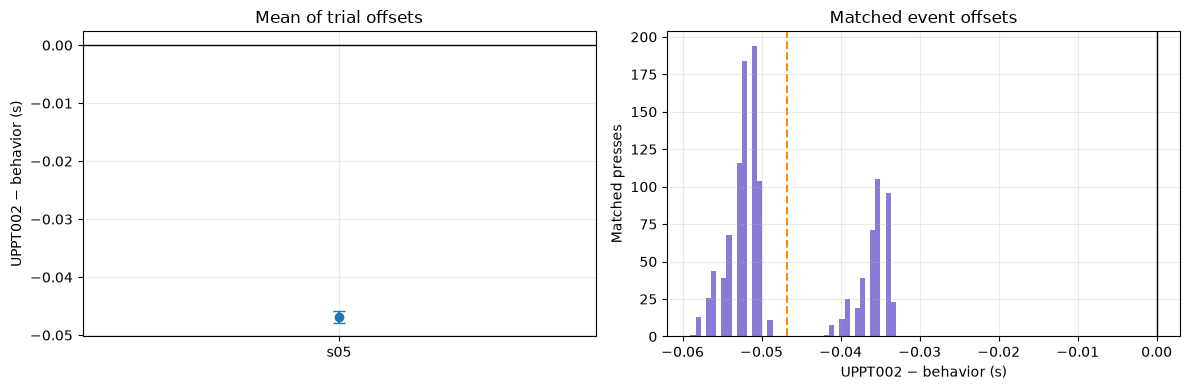

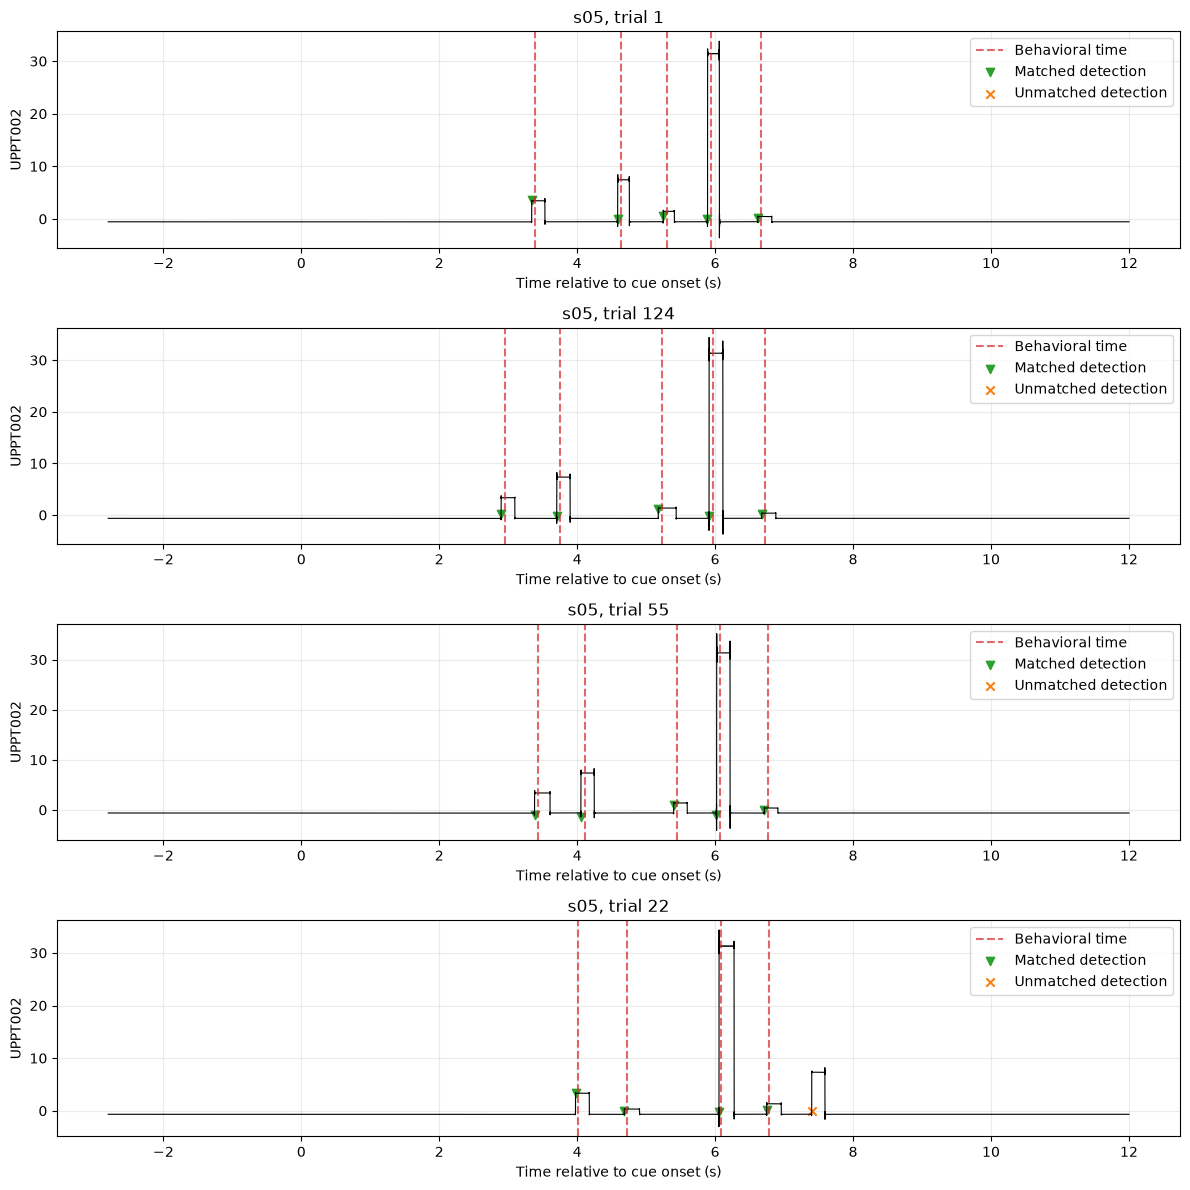

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

mean = summary_table.loc[0, "mean_trial_offset_s"]
low = summary_table.loc[0, "approx_95ci_low_s"]
high = summary_table.loc[0, "approx_95ci_high_s"]

axes[0].errorbar(
    [0], [mean],
    yerr=[[mean - low], [high - mean]],
    fmt="o", capsize=4
)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_xticks([0], [participant])
axes[0].set_ylabel("UPPT002 − behavior (s)")
axes[0].set_title("Mean of trial offsets")
axes[0].grid(alpha=0.25)

axes[1].hist(event_offsets, bins=40, color="slateblue", alpha=0.8)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].axvline(mean, color="darkorange", linestyle="--")
axes[1].set_xlabel("UPPT002 − behavior (s)")
axes[1].set_ylabel("Matched presses")
axes[1].set_title("Matched event offsets")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


def plot_subject_waveforms(trial_numbers=None):
    relative_times = data.times - cue_onset_epoch_s

    if trial_numbers is None:
        trial_numbers = [1]
        if not event_table.empty:
            trial_means = event_table.groupby("trial")["offset_s"].mean()
            median_trial = int((trial_means - trial_means.median()).abs().idxmin())
            largest_trial = int(trial_means.abs().idxmax())
            extra_trials = trial_qc_table.loc[
                trial_qc_table["n_uppt_unmatched"] > 0, "trial"
            ].astype(int).tolist()
            trial_numbers += [median_trial, largest_trial] + extra_trials[:2]

    trial_numbers = list(dict.fromkeys(
        trial for trial in trial_numbers if 1 <= trial <= len(data)
    ))
    fig, axes = plt.subplots(
        len(trial_numbers), 1, figsize=(12, 3 * len(trial_numbers))
    )
    axes = np.atleast_1d(axes)

    for ax, trial in zip(axes, trial_numbers):
        trial_index = trial - 1
        signal = channel[trial_index]
        ax.plot(relative_times, signal, color="black", linewidth=0.8)

        behavior = press_times[trial_index]
        for press_index, time in enumerate(behavior):
            if np.isfinite(time):
                ax.axvline(
                    time, color="tab:red", linestyle="--", alpha=0.7,
                    label="Behavioral time" if press_index == 0 else None
                )

        detected = detected_by_trial[trial_index]
        matched_times = event_table.loc[
            event_table["trial"] == trial, "uppt002_time_s"
        ].to_numpy()
        matched = np.array([
            np.any(np.isclose(matched_times, time, atol=1e-9))
            for time in detected
        ])

        values = np.interp(detected, relative_times, signal)
        ax.scatter(
            detected[matched], values[matched], marker="v",
            color="tab:green", label="Matched detection"
        )
        ax.scatter(
            detected[~matched], values[~matched], marker="x",
            color="tab:orange", label="Unmatched detection"
        )
        ax.set_title(f"{participant}, trial {trial}")
        ax.set_xlabel("Time relative to cue onset (s)")
        ax.set_ylabel("UPPT002")
        ax.grid(alpha=0.25)
        ax.legend(loc="upper right")

    plt.tight_layout()
    plt.show()


plot_subject_waveforms()